# **Solar, Wind and Biomass Energy Efficiency Analysis Using Python**

## **Dataset Information**
- **Dataset name:** Non-Conventional Energy Sources Optimizer
- **Original source:** Hugging Face Datasets
- **Original dataset page:** https://huggingface.co/datasets/SivaMallikarjun/Non-Conventional-Energy-Sources-Optimizer/tree/main
- **Geographic coverage:** Indian states / locations represented in the dataset
- **Time coverage:** No date or year column is supplied
- **Domain:** Renewable energy
- **File format:** CSV
- **Dataset dimensions:** 100,000 rows and 11 columns.


## **Objective**
1. Compare output efficiency across solar, wind and biomass energy records.
2. Examine differences in energy-related environmental conditions across locations.
3. Explore how installation cost, maintenance cost and environmental variables relate to output efficiency and optimized output.
4. Clean and transform the dataset using a reproducible Python workflow.
5. Create meaningful features that support cost and efficiency comparisons.
6. Communicate evidence-based findings and practical considerations.

## **Import Libraries**
Import the required libraries once at the beginning. Reuse them throughout the notebook.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## **Load the Dataset**
Load the CSV only once.

In [ ]:
import pandas as pd

github_url = "https://raw.githubusercontent.com/sathyasathiya0522/Solar-Wind-and-Biomass-Energy-Efficiency-Analysis-Using-Python/refs/heads/main/SORCE%20FILE.csv"

df = pd.read_csv(github_url)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (100000, 11)


,source_type,location,avg_temperature_C,wind_speed_mps,solar_radiation_kWh_m2,humidity_percent,altitude_m,installation_cost_usd,maintenance_cost_usd_year,output_efficiency_percent,optimized_output_kw
0,solar,Telangana,44.7,1.25,6.06,23,271,16890,1651,47.99,435.46
1,solar,Tamil Nadu,33.5,2.69,6.24,36,706,47355,826,82.50,411.54
2,wind,Gujarat,40.6,12.27,3.56,50,1185,36108,504,77.71,281.20
3,wind,Gujarat,16.7,12.05,2.45,80,2408,41466,776,50.82,473.10
4,wind,Gujarat,27.4,14.89,3.32,39,1378,29786,1428,68.38,436.31


## **Initial EDA**

In [ ]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nStatistical summary:")
display(df.describe(include="all").T)

print("\\nMissing values by column:")
display(df.isna().sum().to_frame("missing_count"))

print("\\nDuplicate rows:", df.duplicated().sum())

print("\\nEnergy source counts:")
display(df["source_type"].value_counts(dropna=False))

print("\\nLocation counts:")
display(df["location"].value_counts(dropna=False))

Rows and columns: (100000, 11)
\nColumn names:
['source_type', 'location', 'avg_temperature_C', 'wind_speed_mps', 'solar_radiation_kWh_m2', 'humidity_percent', 'altitude_m', 'installation_cost_usd', 'maintenance_cost_usd_year', 'output_efficiency_percent', 'optimized_output_kw']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   source_type                100000 non-null  object 
 1   location                   100000 non-null  object 
 2   avg_temperature_C          100000 non-null  float64
 3   wind_speed_mps             100000 non-null  float64
 4   solar_radiation_kWh_m2     100000 non-null  float64
 5   humidity_percent           100000 non-null  int64  
 6   altitude_m                 100000 non-null  int64  
 7   installation_cost_usd      100000 non-null  int64  
 8   m

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
source_type,100000,3,wind,33678,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,100000,7,Karnataka,14432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_temperature_C,100000.0,NaN,NaN,NaN,29.966212,8.659263,15.0,22.5,29.9,37.4,45.0
wind_speed_mps,100000.0,NaN,NaN,NaN,7.755127,4.180785,0.5,4.12,7.76,11.37,15.0
solar_radiation_kWh_m2,100000.0,NaN,NaN,NaN,4.508147,1.438994,2.0,3.27,4.52,5.75,7.0
humidity_percent,100000.0,NaN,NaN,NaN,55.09333,20.511423,20.0,37.0,55.0,73.0,90.0
altitude_m,100000.0,NaN,NaN,NaN,1494.37058,867.028165,0.0,745.0,1490.0,2244.0,3000.0
installation_cost_usd,100000.0,NaN,NaN,NaN,30011.93983,11531.282362,10000.0,20000.0,30024.0,39998.25,50000.0
maintenance_cost_usd_year,100000.0,NaN,NaN,NaN,1150.11599,490.469428,300.0,726.0,1149.0,1575.0,2000.0
output_efficiency_percent,100000.0,NaN,NaN,NaN,67.534852,15.880974,40.0,53.77,67.56,81.29,95.0


\nMissing values by column:


,missing_count
source_type,0
location,0
avg_temperature_C,0
wind_speed_mps,0
solar_radiation_kWh_m2,0
humidity_percent,0
altitude_m,0
installation_cost_usd,0
maintenance_cost_usd_year,0
output_efficiency_percent,0


\nDuplicate rows: 0
\nEnergy source counts:


,count
source_type,
wind,33678
solar,33172
biomass,33150


\nLocation counts:


,count
location,
Karnataka,14432
Tamil Nadu,14417
Andhra Pradesh,14361
Gujarat,14239
Rajasthan,14208
Maharashtra,14184
Telangana,14159



# **Data Cleaning, Data Transformation and Feature Engineering**

This stage checks duplicates, missing values, column names, data types and possible outliers. It does not invent missing values or duplicate records. If the original file contains none, report that no treatment was required.

### **1. Check and handle duplicate records**

In [ ]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows before cleaning:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found; no rows were removed.")

print("Shape after duplicate check:", df.shape)

Duplicate rows before cleaning: 0
No duplicate rows found; no rows were removed.
Shape after duplicate check: (100000, 11)


### **2. Check and handle missing values**

In [ ]:
missing_before = df.isna().sum()
display(missing_before.to_frame("missing_before"))

if missing_before.sum() == 0:
    print("No missing values found; imputation was not required.")
else:
    numeric_cols_for_imputation = df.select_dtypes(include="number").columns
    categorical_cols_for_imputation = df.select_dtypes(exclude="number").columns

    for col in numeric_cols_for_imputation:
        if df[col].isna().any():
            df[col] = df[col].fillna(df[col].median())

    for col in categorical_cols_for_imputation:
        if df[col].isna().any():
            mode_values = df[col].mode(dropna=True)
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

print("Total missing values after handling:", df.isna().sum().sum())

,missing_before
source_type,0
location,0
avg_temperature_C,0
wind_speed_mps,0
solar_radiation_kWh_m2,0
humidity_percent,0
altitude_m,0
installation_cost_usd,0
maintenance_cost_usd_year,0
output_efficiency_percent,0


No missing values found; imputation was not required.
Total missing values after handling: 0


### **3. Clean column names and standardize text fields**

In [ ]:
df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True)
              .str.strip("_")
)

for col in ["source_type", "location"]:
    df[col] = df[col].astype("string").str.strip().str.title()

print(df.columns.tolist())
display(df[["source_type", "location"]].head())

['source_type', 'location', 'avg_temperature_c', 'wind_speed_mps', 'solar_radiation_kwh_m2', 'humidity_percent', 'altitude_m', 'installation_cost_usd', 'maintenance_cost_usd_year', 'output_efficiency_percent', 'optimized_output_kw']


,source_type,location
0,Solar,Telangana
1,Solar,Tamil Nadu
2,Wind,Gujarat
3,Wind,Gujarat
4,Wind,Gujarat


### **4. Convert and validate data types**

In [ ]:
numeric_columns = [
    "avg_temperature_c",
    "wind_speed_mps",
    "solar_radiation_kwh_m2",
    "humidity_percent",
    "altitude_m",
    "installation_cost_usd",
    "maintenance_cost_usd_year",
    "output_efficiency_percent",
    "optimized_output_kw"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["source_type"] = df["source_type"].astype("category")
df["location"] = df["location"].astype("category")

print(df.dtypes)
print("Missing values created by numeric conversion:", df.isna().sum().sum())

source_type                  category
location                     category
avg_temperature_c             float64
wind_speed_mps                float64
solar_radiation_kwh_m2        float64
humidity_percent                int64
altitude_m                      int64
installation_cost_usd           int64
maintenance_cost_usd_year       int64
output_efficiency_percent     float64
optimized_output_kw           float64
dtype: object
Missing values created by numeric conversion: 0


### **5. Outlier check (IQR method)**

Outlier flags are diagnostic only. Do not automatically delete valid high or low energy observations. Review domain context before removing any record.

In [ ]:
outlier_summary = []

for col in numeric_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(count)
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)
print("Outliers are flagged for review; no rows are removed automatically.")

,column,lower_bound,upper_bound,outlier_count
0,avg_temperature_c,0.1500,59.7500,0
1,wind_speed_mps,-6.7550,22.2450,0
2,solar_radiation_kwh_m2,-0.4500,9.4700,0
3,humidity_percent,-17.0000,127.0000,0
4,altitude_m,-1503.5000,4492.5000,0
5,installation_cost_usd,-9997.3750,69995.6250,0
6,maintenance_cost_usd_year,-547.5000,2848.5000,0
7,output_efficiency_percent,12.4900,122.5700,0
8,optimized_output_kw,-233.2225,742.5575,0


Outliers are flagged for review; no rows are removed automatically.


### **6. Feature Engineering**

Create features with clear meanings and formulas:
- `total_first_year_cost_usd`: installation cost plus one year of maintenance.
- `optimized_output_per_1000_usd`: optimized output divided by installation cost, scaled per $1,000.
- `efficiency_band`: descriptive category based on output efficiency. These thresholds are project-defined categories, not official industry standards.
- `location_source`: combined location and energy source for grouping.

In [ ]:
df["total_first_year_cost_usd"] = (
    df["installation_cost_usd"] + df["maintenance_cost_usd_year"]
)

df["optimized_output_per_1000_usd"] = (
    df["optimized_output_kw"] / df["installation_cost_usd"] * 1000
)

df["efficiency_band"] = pd.cut(
    df["output_efficiency_percent"],
    bins=[-np.inf, 60, 75, np.inf],
    labels=["Low (<=60%)", "Medium (60-75%)", "High (>75%)"],
    right=True
)

df["location_source"] = (
    df["location"].astype("string") + " - " +
    df["source_type"].astype("string")
)

display(df[[
    "source_type", "location", "installation_cost_usd",
    "maintenance_cost_usd_year", "total_first_year_cost_usd",
    "optimized_output_kw", "optimized_output_per_1000_usd",
    "output_efficiency_percent", "efficiency_band", "location_source"
]].head())

,source_type,location,installation_cost_usd,maintenance_cost_usd_year,total_first_year_cost_usd,optimized_output_kw,optimized_output_per_1000_usd,output_efficiency_percent,efficiency_band,location_source
0,Solar,Telangana,16890,1651,18541,435.46,25.782120,47.99,Low (<=60%),Telangana - Solar
1,Solar,Tamil Nadu,47355,826,48181,411.54,8.690529,82.50,High (>75%),Tamil Nadu - Solar
2,Wind,Gujarat,36108,504,36612,281.20,7.787748,77.71,High (>75%),Gujarat - Wind
3,Wind,Gujarat,41466,776,42242,473.10,11.409347,50.82,Low (<=60%),Gujarat - Wind
4,Wind,Gujarat,29786,1428,31214,436.31,14.648157,68.38,Medium (60-75%),Gujarat - Wind


### **7. Final EDA after cleaning and feature engineering**

In [ ]:
print("Final dataset shape:", df.shape)
print("Total missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\\nData types:")
print(df.dtypes)
print("\\nNumerical summary:")
display(df.describe().T)

Final dataset shape: (100000, 15)
Total missing values: 0
Duplicate rows: 0
\nData types:
source_type                            category
location                               category
avg_temperature_c                       float64
wind_speed_mps                          float64
solar_radiation_kwh_m2                  float64
humidity_percent                          int64
altitude_m                                int64
installation_cost_usd                     int64
maintenance_cost_usd_year                 int64
output_efficiency_percent               float64
optimized_output_kw                     float64
total_first_year_cost_usd                 int64
optimized_output_per_1000_usd           float64
efficiency_band                        category
location_source                  string[python]
dtype: object
\nNumerical summary:


,count,mean,std,min,25%,50%,75%,max
avg_temperature_c,100000.0,29.966212,8.659263,15.000000,22.500000,29.90000,37.400000,45.000000
wind_speed_mps,100000.0,7.755127,4.180785,0.500000,4.120000,7.76000,11.370000,15.000000
solar_radiation_kwh_m2,100000.0,4.508147,1.438994,2.000000,3.270000,4.52000,5.750000,7.000000
humidity_percent,100000.0,55.093330,20.511423,20.000000,37.000000,55.00000,73.000000,90.000000
altitude_m,100000.0,1494.370580,867.028165,0.000000,745.000000,1490.00000,2244.000000,3000.000000
installation_cost_usd,100000.0,30011.939830,11531.282362,10000.000000,20000.000000,30024.00000,39998.250000,50000.000000
maintenance_cost_usd_year,100000.0,1150.115990,490.469428,300.000000,726.000000,1149.00000,1575.000000,2000.000000
output_efficiency_percent,100000.0,67.534852,15.880974,40.000000,53.770000,67.56000,81.290000,95.000000
optimized_output_kw,100000.0,254.933357,141.168066,10.010000,132.695000,255.35000,376.640000,500.000000
total_first_year_cost_usd,100000.0,31162.055820,11542.256826,10305.000000,21135.000000,31190.50000,41142.000000,51941.000000



# **Statistical Analysis & Visualizations**

## **Measure of Central Tendency**
Calculate mean, median and mode of output efficiency for each energy source.

In [ ]:
central_tendency = df.groupby("source_type", observed=True)["output_efficiency_percent"].agg(
    mean="mean",
    median="median",
    mode=lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
).round(2)

display(central_tendency)

,mean,median,mode
source_type,,,
Biomass,67.47,67.43,89.00
Solar,67.53,67.71,45.78
Wind,67.60,67.54,87.49


**Interpretation:**

Compare the mean, median and mode for solar, wind and biomass. Values that are close indicate similar central efficiency levels. Use the displayed results rather than assuming one source is meaningfully better.

## **Variance and Standard Deviation**

In [ ]:
dispersion = df.groupby("source_type", observed=True)["output_efficiency_percent"].agg(
    variance="var",
    standard_deviation="std"
).round(2)

display(dispersion)

,variance,standard_deviation
source_type,,
Biomass,252.13,15.88
Solar,253.45,15.92
Wind,251.06,15.84


**Interpretation:**

 Variance and standard deviation describe how spread out efficiency values are within each source. A larger standard deviation means greater variation in the records; it does not by itself mean lower performance.

## **Skewness, Kurtosis and Box Plot**

,skewness,kurtosis
source_type,,
Biomass,0.007,-1.201
Solar,-0.010,-1.206
Wind,-0.007,-1.190


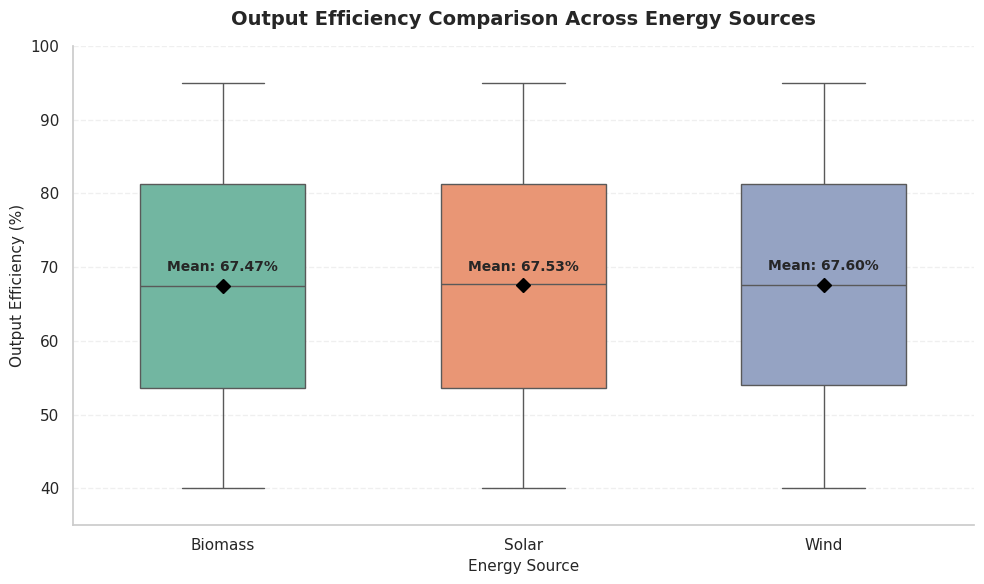

In [ ]:
# Skewness and Kurtosis
shape_stats = df.groupby("source_type", observed=True)["output_efficiency_percent"].agg(
    skewness="skew",
    kurtosis=lambda x: x.kurt()
).round(3)

display(shape_stats)

# Professional Box Plot
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df,
    x="source_type",
    y="output_efficiency_percent",
    hue="source_type",
    palette="Set2",
    width=0.55,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7
    },
    legend=False
)

# Add mean value labels
means = df.groupby("source_type", observed=True)["output_efficiency_percent"].mean()

for i, value in enumerate(means):
    ax.text(i, value + 2, f"Mean: {value:.2f}%",
            ha="center", fontsize=10, fontweight="bold")

plt.title("Output Efficiency Comparison Across Energy Sources",
          fontsize=14, fontweight="bold", pad=15)

plt.xlabel("Energy Source", fontsize=11)
plt.ylabel("Output Efficiency (%)", fontsize=11)
plt.ylim(35, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()

**Interpretation:**

The box plot shows that all three energy sources have similar output efficiency distributions. Wind has the highest mean efficiency at 67.60%, followed by Solar at 67.53% and Biomass at 67.47%. The similar distribution ranges indicate that there is no major difference in output efficiency among the three sources.

## **Visualizations**

- **Univariate analysis:** distribution of one variable.
- **Bivariate analysis:** relationship or comparison between two variables.
- **Multivariate analysis:** patterns involving three or more variables.

Every chart below is in its own code cell and is followed by an interpretation prompt.

# **1. Univariate Analysis**

### **Chart 1 — Output Efficiency Distribution by Energy Source**

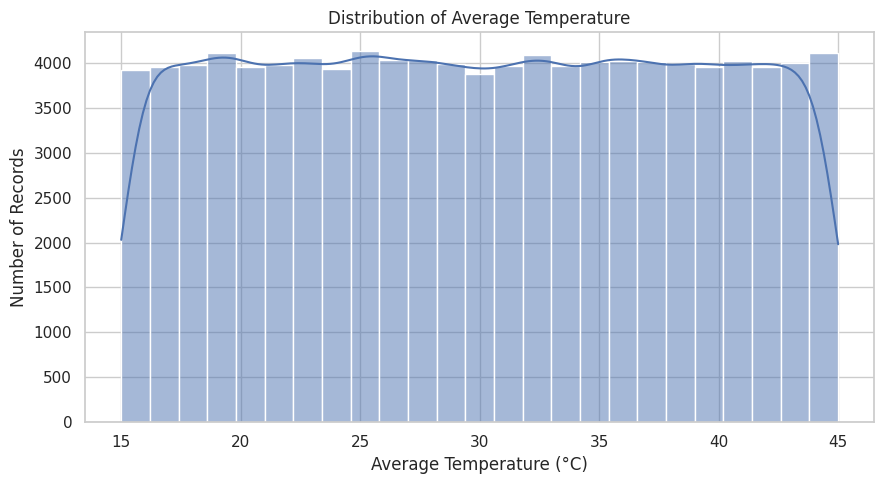

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='avg_temperature_c',
    bins=25,
    kde=True
)

plt.title('Distribution of Average Temperature')
plt.xlabel('Average Temperature (°C)')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()

**Interpretation:**

The histogram shows the distribution of average temperature values in the dataset. Temperature values range approximately from 15°C to 45°C. The number of records is fairly consistent across the temperature ranges, indicating a nearly uniform distribution. No major peaks or significant gaps are observed.

### **Chart 2 — Percentage Distribution of Records by Energy Source**

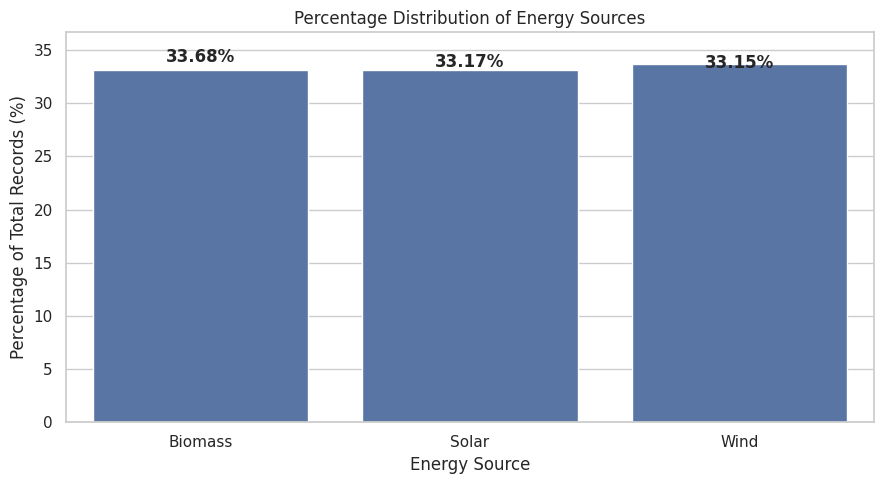

In [ ]:
source_counts = df['source_type'].value_counts()

source_percentage = (
    source_counts / source_counts.sum()
) * 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=source_percentage.index,
    y=source_percentage.values
)

for i, value in enumerate(source_percentage.values):
    ax.text(i, value + 0.2, f'{value:.2f}%',
            ha='center', fontweight='bold')

plt.title('Percentage Distribution of Energy Sources')
plt.xlabel('Energy Source')
plt.ylabel('Percentage of Total Records (%)')
plt.ylim(0, max(source_percentage.values) + 3)
plt.tight_layout()
plt.show()

**Interpretation:** Compare the record counts for solar, wind and biomass. This chart describes dataset representation, not which source generates more electricity.

### **Chart 3 — Average Installation Cost by Energy Source**

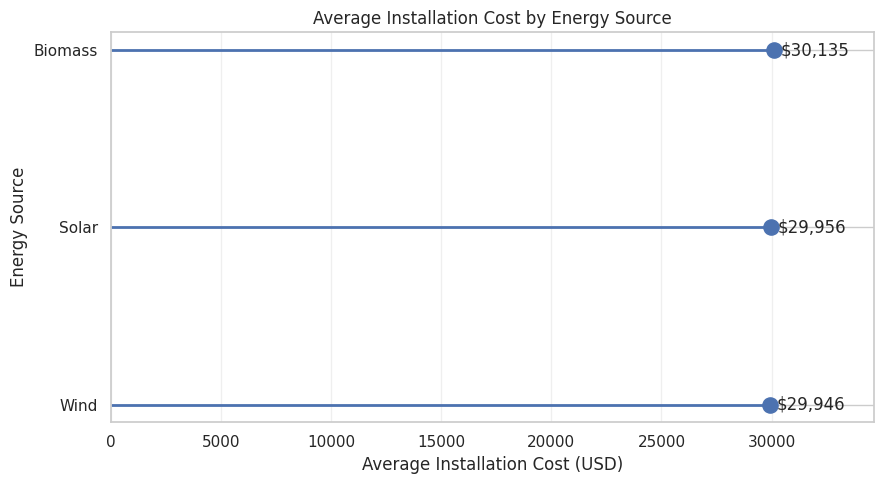

In [ ]:
cost_avg = df.groupby('source_type', observed=True)['installation_cost_usd'].mean().sort_values()

plt.figure(figsize=(9, 5))

plt.hlines(
    y=cost_avg.index,
    xmin=0,
    xmax=cost_avg.values,
    linewidth=2
)

plt.scatter(
    cost_avg.values,
    cost_avg.index,
    s=120
)

for x, y in zip(cost_avg.values, cost_avg.index):
    plt.text(x + 300, y, f'${x:,.0f}', va='center')

plt.title('Average Installation Cost by Energy Source')
plt.xlabel('Average Installation Cost (USD)')
plt.ylabel('Energy Source')
plt.xlim(0, cost_avg.max() * 1.15)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:**


The lollipop chart compares the average installation cost across Solar, Wind, and Biomass energy sources. Biomass has the highest average installation cost at approximately USD 30,135. Solar follows at USD 29,956, while Wind has the lowest average cost at USD 29,946. The cost differences are very small, indicating similar average installation costs across all three energy sources.

# **2. Bivariate Analysis**

### **Chart 1 — Installation Cost vs Output Efficiency**

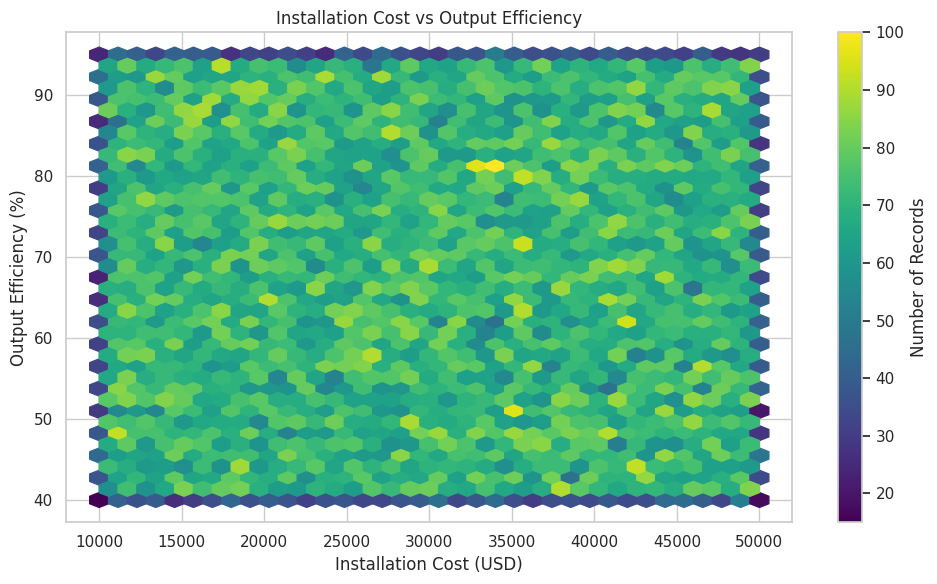

Pearson Correlation:
-0.004


In [ ]:
plt.figure(figsize=(10, 6))

plt.hexbin(
    df['installation_cost_usd'],
    df['output_efficiency_percent'],
    gridsize=35,
    mincnt=1,
    cmap='viridis'
)

plt.colorbar(label='Number of Records')

plt.title('Installation Cost vs Output Efficiency')
plt.xlabel('Installation Cost (USD)')
plt.ylabel('Output Efficiency (%)')

plt.tight_layout()
plt.show()

print("Pearson Correlation:")
print(
    df['installation_cost_usd']
    .corr(df['output_efficiency_percent']).round(3)
)

**Interpretation:** The Hexbin plot shows the distribution of records across installation cost and output efficiency. The data points are spread across different cost and efficiency ranges without a clear visible pattern. This indicates that installation cost has a very weak relationship with output efficiency. The Pearson correlation value also supports this observation.

### **Chart 2 — Comparison of Mean and Median Output Efficiency Across Energy Source**

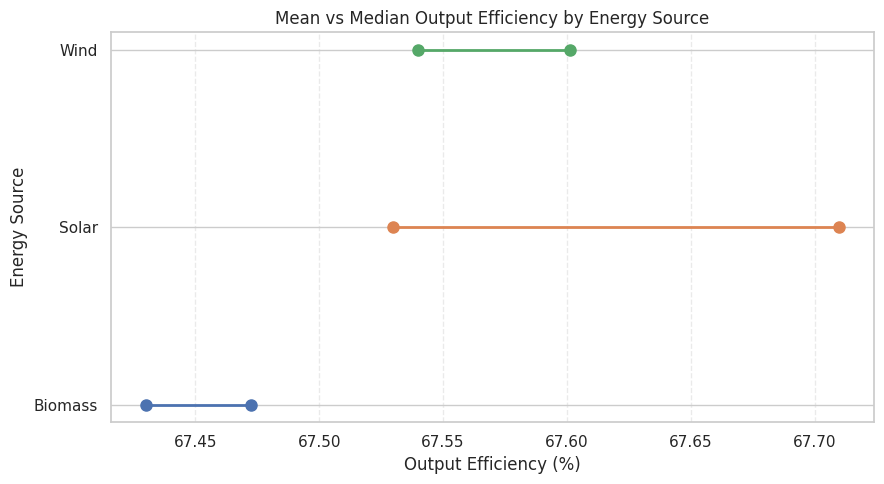

,mean,median
source_type,,
Biomass,67.472,67.43
Solar,67.530,67.71
Wind,67.601,67.54


In [ ]:
summary = df.groupby('source_type', observed=False)[
    'output_efficiency_percent'
].agg(['mean', 'median']).sort_values('mean')

plt.figure(figsize=(9, 5))

for i, (source, row) in enumerate(summary.iterrows()):
    plt.plot(
        [row['mean'], row['median']],
        [i, i],
        marker='o',
        linewidth=2,
        markersize=8
    )

plt.yticks(range(len(summary)), summary.index)
plt.xlabel('Output Efficiency (%)')
plt.ylabel('Energy Source')
plt.title('Mean vs Median Output Efficiency by Energy Source')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

display(summary.round(3))

**Interpretation:**

The dumbbell plot compares the mean and median output efficiency of Solar, Wind, and Biomass energy sources. Biomass shows a small difference between its mean and median values, while Wind also has a relatively small difference. Solar shows a comparatively larger difference between the two measures. Overall, the chart helps compare the central tendency of output efficiency across the three energy sources.

### **Chart 3 — Correlation heatmap of numerical variables**

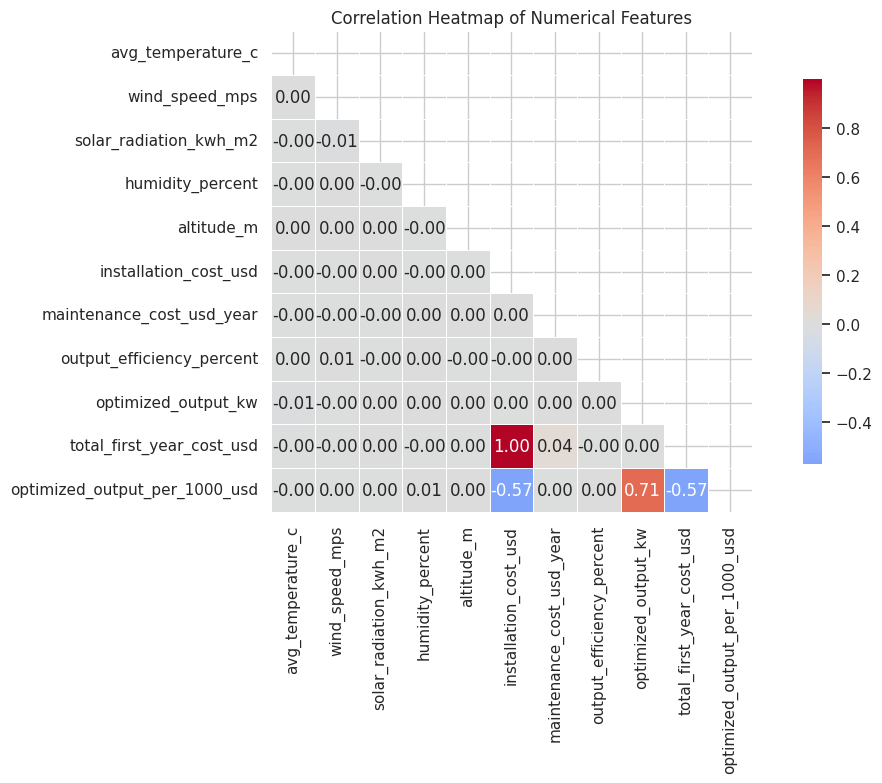

In [ ]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation
corr_matrix = numeric_df.corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

**Interpretation:**

The correlation heatmap shows the relationships between numerical variables in the dataset. Optimized output and optimized output per 1000 USD show a positive correlation of 0.71. Installation cost and optimized output per 1000 USD show a negative correlation of -0.57. Most environmental variables have very weak correlations with the other numerical variables. Overall, the heatmap helps identify important relationships among the dataset features.

# **3. Multivariate Analysis**

### **Chart 1 — Average Output Efficiency Heatmap by Location and Energy Source**

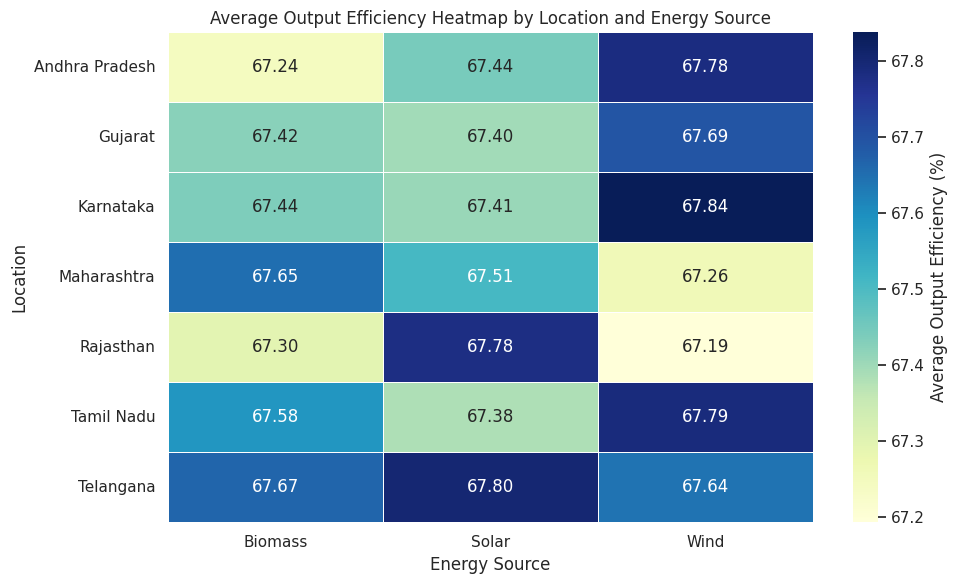

In [ ]:
location_pivot = df.pivot_table(
    index='location',
    columns='source_type',
    values='output_efficiency_percent',
    aggfunc='mean',
    observed=False
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    location_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Average Output Efficiency (%)'}
)

plt.title('Average Output Efficiency Heatmap by Location and Energy Source')
plt.xlabel('Energy Source')
plt.ylabel('Location')

plt.tight_layout()
plt.show()

**Interpretation:**

The heatmap compares the average output efficiency of Solar, Wind, and Biomass energy sources across different locations. Wind energy shows the highest efficiency in Karnataka at 67.84%, while Biomass records the lowest efficiency in Rajasthan at 67.19%. Solar energy performs relatively well in Rajasthan and Telangana. Overall, the heatmap highlights variations in energy efficiency across different locations and energy sources.

### **Chart 2 — Average Optimized Output Comparison by Energy Source**

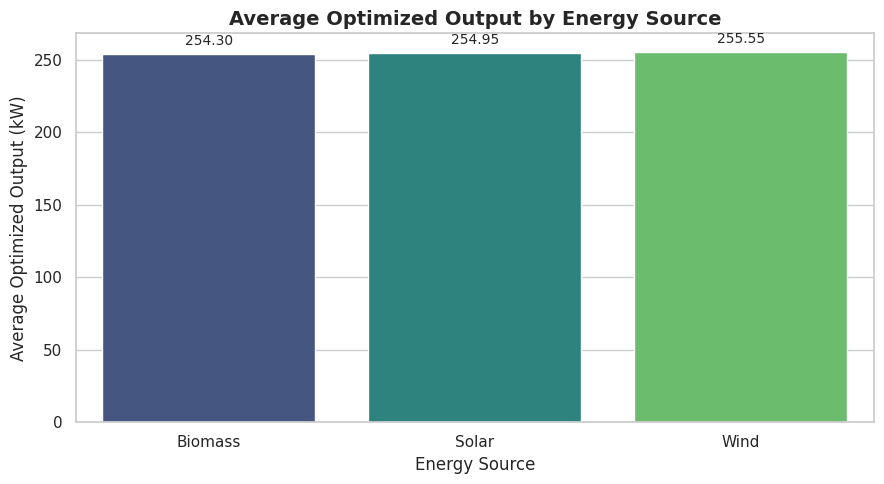

In [ ]:
# Average Optimized Output by Energy Source

output_avg = (
    df.groupby("source_type", observed=True)["optimized_output_kw"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=output_avg.index,
    y=output_avg.values,
    hue=output_avg.index,
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=4, fontsize=10)

plt.title("Average Optimized Output by Energy Source",
          fontsize=14, fontweight="bold")
plt.xlabel("Energy Source")
plt.ylabel("Average Optimized Output (kW)")
plt.tight_layout()
plt.show()

**Interpretation:**

The chart compares average optimized output across the three energy sources. Wind has the highest average output (255.35 kW), followed by Solar (254.95 kW) and Biomass (254.30 kW). The differences are very small.

### **Chart 3 — Efficiency and First-Year Cost Comparison**

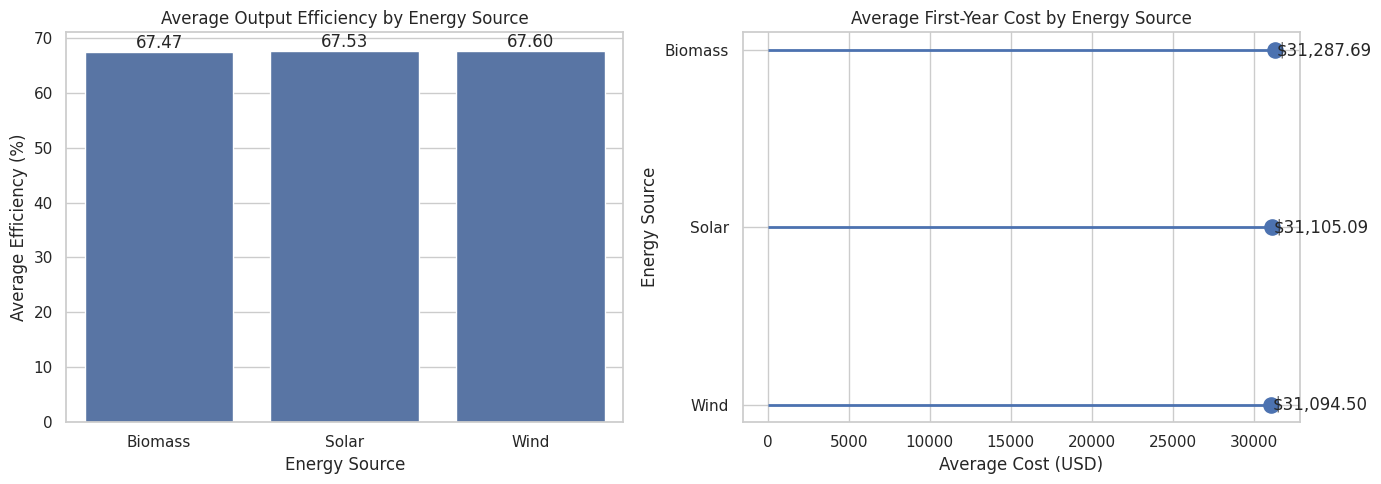

,source_type,average_efficiency,average_first_year_cost
0,Biomass,67.47,31287.69
1,Solar,67.53,31105.09
2,Wind,67.60,31094.50


In [ ]:
# Calculate summary
summary = df.groupby(
    'source_type',
    observed=False
).agg(
    average_efficiency=('output_efficiency_percent', 'mean'),
    average_first_year_cost=('total_first_year_cost_usd', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Average Efficiency
sns.barplot(
    data=summary,
    x='source_type',
    y='average_efficiency',
    ax=axes[0]
)

axes[0].set_title('Average Output Efficiency by Energy Source')
axes[0].set_xlabel('Energy Source')
axes[0].set_ylabel('Average Efficiency (%)')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f')

# Chart 2: Average First-Year Cost
cost_data = summary.sort_values('average_first_year_cost')

axes[1].hlines(
    y=cost_data['source_type'],
    xmin=0,
    xmax=cost_data['average_first_year_cost'],
    linewidth=2
)

axes[1].scatter(
    cost_data['average_first_year_cost'],
    cost_data['source_type'],
    s=120
)

for x, y in zip(
    cost_data['average_first_year_cost'],
    cost_data['source_type']
):
    axes[1].text(x + 100, y, f'${x:,.2f}', va='center')

axes[1].set_title('Average First-Year Cost by Energy Source')
axes[1].set_xlabel('Average Cost (USD)')
axes[1].set_ylabel('Energy Source')

plt.tight_layout()
plt.show()

display(summary.round(2))

**Interpretation:**

The comparison shows that Wind has the highest average output efficiency (67.60%) and the lowest average first-year cost (USD 31,094.50).

Biomass has the lowest average efficiency (67.47%) and the highest average first-year cost (USD 31,287.69).

Solar records an average efficiency of 67.53% with an average first-year cost of USD 31,105.09.

Overall, the differences between the three energy sources are small.

# **Stage 4**
# **Documentation, Insights & Presentation**

## **1. Summary of Findings (Plain English)**

This project explores a dataset of solar, wind and biomass energy records using Python. It reviews data quality, creates derived cost and efficiency features, summarizes efficiency statistics, and visualizes comparisons by source and location. The dataset has no date field, so the analysis is cross-sectional rather than a time-trend study.

## **2. Key Insights**

1. **Efficiency Comparison:** Wind energy has the highest average output efficiency at 67.60%, followed by Solar at 67.53% and Biomass at 67.47%.

2. **Variation:** The standard deviation values are very close: Solar (15.92), Wind (15.84), and Biomass (15.88). This indicates similar variation in output efficiency across the three energy sources.

3. **Cost Comparison:** Biomass has the highest average first-year cost of USD 31,287.69, while Wind has the lowest at USD 31,094.50. Wind also has the lowest average annual maintenance cost at approximately USD 1,148.23.

4. **Location Differences:** Wind shows the highest average efficiency in Karnataka at 67.84%, while Biomass records the lowest in Rajasthan at 67.19%.

5. **Relationships:** The correlation analysis shows a positive correlation of 0.71 between optimized output and optimized output per 1000 USD. Installation cost and optimized output per 1000 USD show a negative correlation of -0.57.

## **3. Types of Analysis**

### **Descriptive Analysis**
Used summary statistics, frequency counts and charts to describe efficiency, costs, environmental variables and source representation.

### **Diagnostic Analysis**
Used grouped comparisons, Hexbin plots, trend analysis and correlation analysis to explore how output efficiency and optimized output vary across energy sources, locations, installation costs and environmental variables. These analyses identify associations and patterns but do not prove causation.

### **Predictive Analysis**
A predictive model is not included in this version. The dataset has no date column, and a reliable prediction target and validation strategy must be justified before fitting a model. This can be added as a separate extension if required.

### **Prescriptive Analysis**
The derived cost and efficiency measures can support preliminary comparisons. Any investment decision must also consider local resource conditions, project lifetime, financing, tariffs, reliability and verified technical data not included here.

## **4. Recommendations / Decision Support**
- Compare energy sources using efficiency and both installation and maintenance costs rather than one metric alone.
- Use location-level results as screening evidence, then validate with local engineering and resource assessments.
- Treat optimized output as the dataset's supplied optimized measure, not as verified actual generation.
- Avoid selecting a technology from a small difference in average efficiency alone.

## **5. Conclusion**

Python enabled a structured review of renewable-energy records, data quality, engineered cost indicators, statistical summaries and visual comparisons. The analysis supports a transparent comparison of solar, wind and biomass records in this dataset. Conclusions are limited to the variables and locations represented in the supplied file.

# **Future Enhancement**
- Add verified time-series generation data to analyze annual trends.
- Validate the dataset's definitions and units with the original publisher.
- Add project lifetime, capacity and energy-yield information for stronger cost comparisons.
- Build a dashboard in Power BI or Tableau.
- Develop a predictive model only after defining a suitable target, checking assumptions and validating performance against a baseline.